Abhishek Pillai (arp2247)

# MNIST Sign Language

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics         import accuracy_score
from sklearn.model_selection import train_test_split

import keras
from keras.utils  import to_categorical
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout

In [2]:
class SignLanguage:
    def __init__(self):
        self.model = None
        
        self.data = {
            "train": None,
            "test" : None
        }
        self.create_model()
    
    def create_model(self):
        """
        Create a CNN model and save it to self.model
        """
        
        model = Sequential([
            keras.Input(shape=(28, 28, 1)),
            Conv2D(32, (3, 3), activation='relu'),
            MaxPooling2D((2, 2)),
            Dropout(0.25),
            Conv2D(64, (3, 3), activation='relu'),
            MaxPooling2D((2, 2)),
            Dropout(0.25),
            Conv2D(128, (3, 3), activation='relu'),
            Dropout(0.25),
            Flatten(),
            Dense(128, activation='relu'),
            Dropout(0.5),
            Dense(25, activation='softmax'),   # labels 0-24 (9 = J is never used)
        ])

        model.compile('adam', loss=keras.losses.categorical_crossentropy, metrics=['accuracy'])
        
        self.model = model
    
    def prepare_data(self, images, labels):
        """
        Use this method to normalize the dataset and split it into training and validation sets.
        Save your data in self.data["train"] and self.data["test"] as a tuple
        of (images, labels). Note: self.data["test"] holds your VALIDATION set,
        not the real test set (the grading script keeps that separate).
        
        :param images numpy array of size (num_examples, 28*28)
        :param labels numpy array of size (num_examples, )
        """
        x = self._preprocess(images)
        y = to_categorical(labels, num_classes=25)

        x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.1)

        self.data = {
            "train": (x_train, y_train),
            "test" : (x_val, y_val),
        }
    
    def train(self, batch_size:int=128, epochs:int=30, verbose:int=1):
        """
        Use model.fit() to train your model. Make sure to return the history for a neat visualization.
        Pass your validation set to model.fit() (validation_data=...), so the history
        contains 'val_accuracy' for visualize_accuracy().
        
        :param batch_size The batch size to use for training
        :param epochs     Number of epochs to use for training
        :param verbose    Whether or not to print training output
        """
        
        history = self.model.fit(
            self.data["train"][0], self.data["train"][1],
            batch_size=batch_size,
            epochs=epochs,
            verbose=verbose,
            validation_data=self.data["test"],
        )
        return history
    
    def predict(self, data):
        """
        Use the trained model to predict labels for test data.
        
        :param data: numpy array of size (num_examples, 28*28), raw pixel values 0-255
        :return a numpy array of integer class labels (0 to 24). array size = (num_examples, )
        """
        
        # Normalize the data in the same way as training data
        x = self._preprocess(data)
        probs = self.model.predict(x, verbose=0)
        return np.argmax(probs, axis=1)

    @staticmethod
    def _preprocess(images):
        """Scale raw 0-255 pixel rows to [0, 1] and reshape to (n, 28, 28, 1)."""
        x = np.asarray(images, dtype='float32') / 255.0
        return x.reshape(-1, 28, 28, 1)
    
    def visualize_data(self, data):
        """
        Visualizing the hand gestures
        
        :param data: numpy array of images
        """
        if data is None: return
        
        nrows, ncols = 5, 5
        fig, axs = plt.subplots(nrows, ncols, figsize=(10, 10), sharex=True, sharey=True)
        plt.subplots_adjust(wspace=0, hspace=0)

        for i in range(nrows):
            for j in range(ncols):
                axs[i][j].imshow(data[0][i*ncols+j].reshape(28, 28), cmap='gray')
        plt.show()

    def visualize_accuracy(self, history):
        """
        Plots out the accuracy measures given a keras history object
        
        :param history: return value from model.fit()
        """
        if history is None: return
        
        plt.plot(history.history['accuracy'])
        plt.plot(history.history['val_accuracy'])
        plt.title("Accuracy")
        plt.xlabel('epoch')
        plt.ylabel('accuracy')
        plt.legend(['train','validation'])
        plt.show()

# Grading Script

Do NOT modify this section

In [3]:
if __name__=="__main__":
    train = pd.read_csv('train.csv')
    test  = pd.read_csv('test.csv')

    train_labels, test_labels = train['label'].values, test['label'].values
    train.drop('label', axis=1, inplace=True)
    test.drop('label', axis=1, inplace=True)

    # Cast to standard Python int to satisfy Keras strict type checking
    num_classes = int(test_labels.max() + 1)
    train_images, test_images = train.values, test.values

    print(train_images.shape, train_labels.shape, test_images.shape, test_labels.shape)

(27455, 784) (27455,) (7172, 784) (7172,)


/var/folders/1c/cf9fmm6542gfxx489fhc6d_40000gn/T/ipykernel_43176/2363179929.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train.drop('label', axis=1, inplace=True)
/var/folders/1c/cf9fmm6542gfxx489fhc6d_40000gn/T/ipykernel_43176/2363179929.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test.drop('label', axis=1, inplace=True)


In [4]:
if __name__=="__main__":
    my_model = SignLanguage()
    my_model.prepare_data(train_images, train_labels)

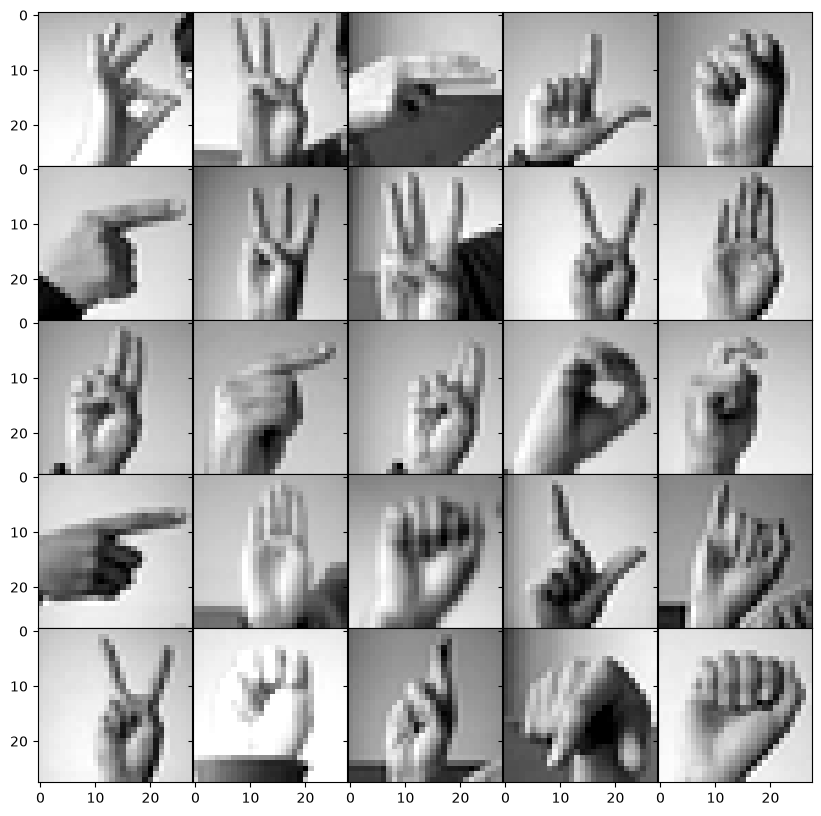

In [5]:
if __name__=="__main__":
    my_model.visualize_data(my_model.data["train"])

Epoch 1/30


  1/194 ━━━━━━━━━━━━━━━━━━━━ 2:48 875ms/step - accuracy: 0.0625 - loss: 3.2266

  6/194 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.0469 - loss: 3.2171   

 11/194 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.0426 - loss: 3.2159

 15/194 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.0417 - loss: 3.2117

 18/194 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.0399 - loss: 3.2112

... (1,443 outputs left out)

182/194 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9942 - loss: 0.0181

186/194 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9942 - loss: 0.0180

191/194 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9942 - loss: 0.0180

194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9942 - loss: 0.0179 - val_accuracy: 1.0000 - val_loss: 2.1337e-05


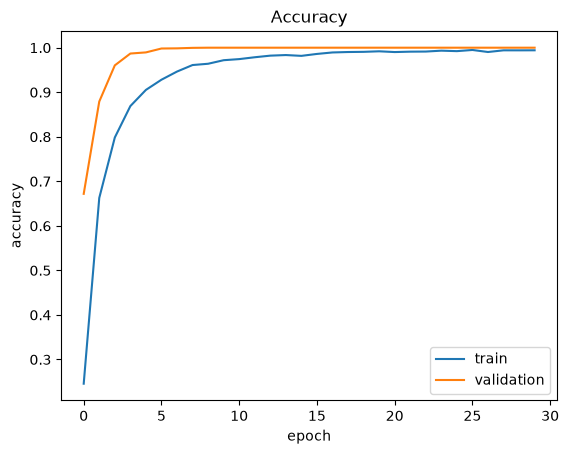

In [6]:
if __name__=="__main__":
    history = my_model.train(epochs=30, verbose=1)
    my_model.visualize_accuracy(history)

In [7]:
if __name__=="__main__":
    y_pred = my_model.predict(test_images)
    accuracy = accuracy_score(test_labels, y_pred)
    print(accuracy)

0.9647239263803681
